# WTI oil: one-day 95% Value at Risk

Daily raw returns, distribution fitting, rolling GH and GJR-GARCH forecasts,
CAViaR, coverage tests, loss functions, and forecast comparison.

**Agreed data revision.** TankerMap's WTI MAX feed begins on **31 May 2006**.
Training: **2006-05-31–2008-12-31**; validation: **2009–2017**;
held-out test: **2018–2025**. The first return is on the next observed date.
The original 2000–2002 / 2003–2017 split cannot be populated from this feed.
The 2026 observations are excluded from the study.

**Conventions.** Write $q_t=Q_{0.05}(r_t\mid\mathcal F_{t-1})$. An exception is
$r_t<q_t$; plots show this signed, usually negative, return threshold.
The positive loss VaR is $-q_t=Q_{0.95}(-r_t)$, not $Q_{0.95}(r_t)$.
All saved returns and forecasts are decimals. The window is **252 × 2 = 504
observations**, not $252^2$, and is not necessarily two calendar years.

**WTI caveat.** This feed contains a negative price on 20 April 2020.
The requested arithmetic returns are retained, including values below −100%.
With negative prices, this ratio is not a conventional invested-wealth return.
TankerMap labels the series WTI/NYMEX but does not document contract rolls here;
this notebook treats it as the published price series, not a tradable continuous
futures total-return strategy. No observations are winsorized, interpolated, or filled.

Run from the project directory using its `.venv` Python kernel. Install dependencies
with `python -m pip install -r requirements.txt`. Daily rolling refits can take many
minutes. Checkpoints in `results/` allow an interrupted run to resume.

## 0. Configuration and utility functions

The implementations are in the adjacent **`var_utils.py`**, keeping the statistical
logic reusable and testable. The notebook below controls every analysis step.
Interpret “Lopless” as **Lopez**, “Cristoffersen” as **Christoffersen**, and
“GJ-GARCH” as **GJR-GARCH**.

For a negative return threshold $q_t$, the losses are:

- Lopez: $I(r_t<q_t)[1+(r_t-q_t)^2]$.
- Blanco–Ihle: $I(r_t<q_t)(r_t-q_t)/q_t$, defined here only when all $q_t<0$.
- Quantile: $[0.05-I(r_t<q_t)](r_t-q_t)$.

Reported loss scores are **means across all evaluation dates**. Lopez is sensitive
to the return units; these are always decimals. Quantile loss is the primary
criterion for comparing quantile forecasts; the two breach-only losses can reward
overly conservative forecasts.

In [1]:
from pathlib import Path
import importlib.metadata
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, normal_ad
from IPython.display import display, Markdown

from var_utils import (
    load_tankermap, coverage_table, require_coverage, raw_returns,
    kupiec_test, christoffersen_test, dq_test, backtest,
    lopez_loss, blanco_ihle_loss, quantile_loss, pairwise_dm,
    fit_distributions, information_criteria, GARCH_SPECS,
    fit_garch, garch_quantile, fit_caviar, caviar_gradient,
    rolling_forecasts, complete_quantiles, plot_var,
)

ALPHA = 0.05
SEED = 2026
WINDOW = 252 * 2
GH_WORKERS = 4  # Independent local fits; use 1 if multiprocessing is unavailable.
STUDY_START = '2006-05-31'
STUDY_END = '2025-12-31'
TRAIN_END = '2008-12-31'
VALID_START, VALID_END = '2009-01-01', '2017-12-31'
TEST_START, TEST_END = '2018-01-01', '2025-12-31'
REFRESH_DATA = False  # Use the included, reproducible MAX-feed snapshot.
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10})
pd.set_option('display.max_columns', 30)
versions = {name: importlib.metadata.version(name)
            for name in ['numpy', 'pandas', 'scipy', 'statsmodels', 'arch', 'numba']}
display(pd.Series(versions, name='version'))

/Users/andreikh./Repositories/var-estimation/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy           2.5.4
pandas          3.1.0
scipy          1.18.1
statsmodels    0.15.0
arch            8.0.0
numba          0.68.0
Name: version, dtype: str

## 1. Parse TankerMap's daily WTI prices

Read the verified JSON endpoint with `period=MAX` and use the daily **close** in
USD per barrel. A raw snapshot and provenance record live in `data/`.
Duplicates and nonfinite prices are errors. The coverage table exposes gaps;
the guard rejects missing years or severely incomplete years. Holiday calendars
vary, so the observation-count check is a coarse audit, not a claim of perfect coverage.

Source: [TankerMap WTI](https://tankermap.com/market-data/wti),
[MAX feed](https://tankermap.com/api/market-data/wti?period=MAX).

In [2]:
all_prices, source_metadata = load_tankermap(refresh=REFRESH_DATA)
prices = all_prices.loc[STUDY_START:STUDY_END].copy()
display(pd.Series(source_metadata, name='TankerMap metadata'))
coverage = coverage_table(prices, 2006, 2025)
display(coverage)
require_coverage(prices, STUDY_START, STUDY_END)
prices.to_csv(RESULTS / 'wti_prices_2006_2025.csv')
display(prices.head().to_frame(), prices.tail().to_frame())
print(f'{len(prices):,} prices; {prices.index.min().date()} to {prices.index.max().date()}')
print('Nonpositive prices (preserved):')
display(prices[prices <= 0].to_frame())

lastUpdated                           2026-10-23T23:56:50.669892+00:00
freshnessWindow                                                  1 day
aggregationWindow                                                  MAX
source               TankerMap market feed from KuzTerm daily OHLC ...
warnings                                                  [stale_data]
Name: TankerMap metadata, dtype: object

,observations,first,last
year,,,
2006,148,2006-05-31,2006-12-29
2007,254,2007-01-02,2007-12-31
2008,253,2008-01-02,2008-12-31
2009,252,2009-01-02,2009-12-31
2010,252,2010-01-04,2010-12-31
2011,252,2011-01-03,2011-12-30
2012,252,2012-01-03,2012-12-31
2013,252,2013-01-02,2013-12-31
2014,252,2014-01-02,2014-12-31


,WTI_USD_per_barrel
date,
2006-05-31,71.29
2006-06-01,70.34
2006-06-02,72.33
2006-06-05,72.60
2006-06-06,72.50


,WTI_USD_per_barrel
date,
2025-12-24,58.35
2025-12-26,56.74
2025-12-29,58.08
2025-12-30,57.95
2025-12-31,57.42


4,935 prices; 2006-05-31 to 2025-12-31
Nonpositive prices (preserved):


,WTI_USD_per_barrel
date,
2020-04-20,-37.63


## 2. Raw returns and chronological splits

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}.$$

Calculate returns **before splitting** so the first validation/test return uses
the preceding observed price. “Daily” means consecutive published observations;
weekends and holidays are not filled. A zero denominator raises an error.

As requested, model comparison below pools training and validation data through
2017. This is an in-sample development exercise, not a separate validation
backtest or hyperparameter search. Model families and the 504-day window are
fixed before evaluating 2018–2025. On the first test date, the rolling window
ends in 2017; using the old training block instead would not be a rolling forecast.

In [3]:
returns = raw_returns(prices)
train = returns.loc[:TRAIN_END]
validation = returns.loc[VALID_START:VALID_END]
development = returns.loc[:VALID_END]
test = returns.loc[TEST_START:TEST_END]
splits = {'Training': train, 'Validation': validation, 'Test': test}
split_table = pd.DataFrame({name: {'first_return': x.index.min(), 'last_return': x.index.max(),
                                  'n': len(x), 'mean': x.mean(), 'std': x.std()}
                            for name, x in splits.items()}).T
display(split_table)
assert len(train) >= WINDOW and len(test) > 0
assert len(train) + len(validation) + len(test) == len(returns)
assert development.index.max() < test.index.min()
returns.to_csv(RESULTS / 'wti_raw_returns.csv')
split_table.to_csv(RESULTS / 'sample_splits.csv')
display(returns.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())

,first_return,last_return,n,mean,std
Training,2006-06-01 00:00:00,2008-12-31 00:00:00,654,-0.00038,0.025959
Validation,2009-01-02 00:00:00,2017-12-29 00:00:00,2267,0.000389,0.022612
Test,2018-01-02 00:00:00,2025-12-31 00:00:00,2013,-0.001559,0.079498


,return
count,4934.000000
mean,-0.000508
std,0.053875
min,-3.059661
1%,-0.069177
5%,-0.037897
50%,0.000956
95%,0.035196
99%,0.066753
max,0.250996


## 3. Full-period exploration

The full-period plots are descriptive only. They do not determine model choices.
The extra central histogram panel makes the bulk of the distribution visible
while the full histogram retains the extreme April 2020 observations.

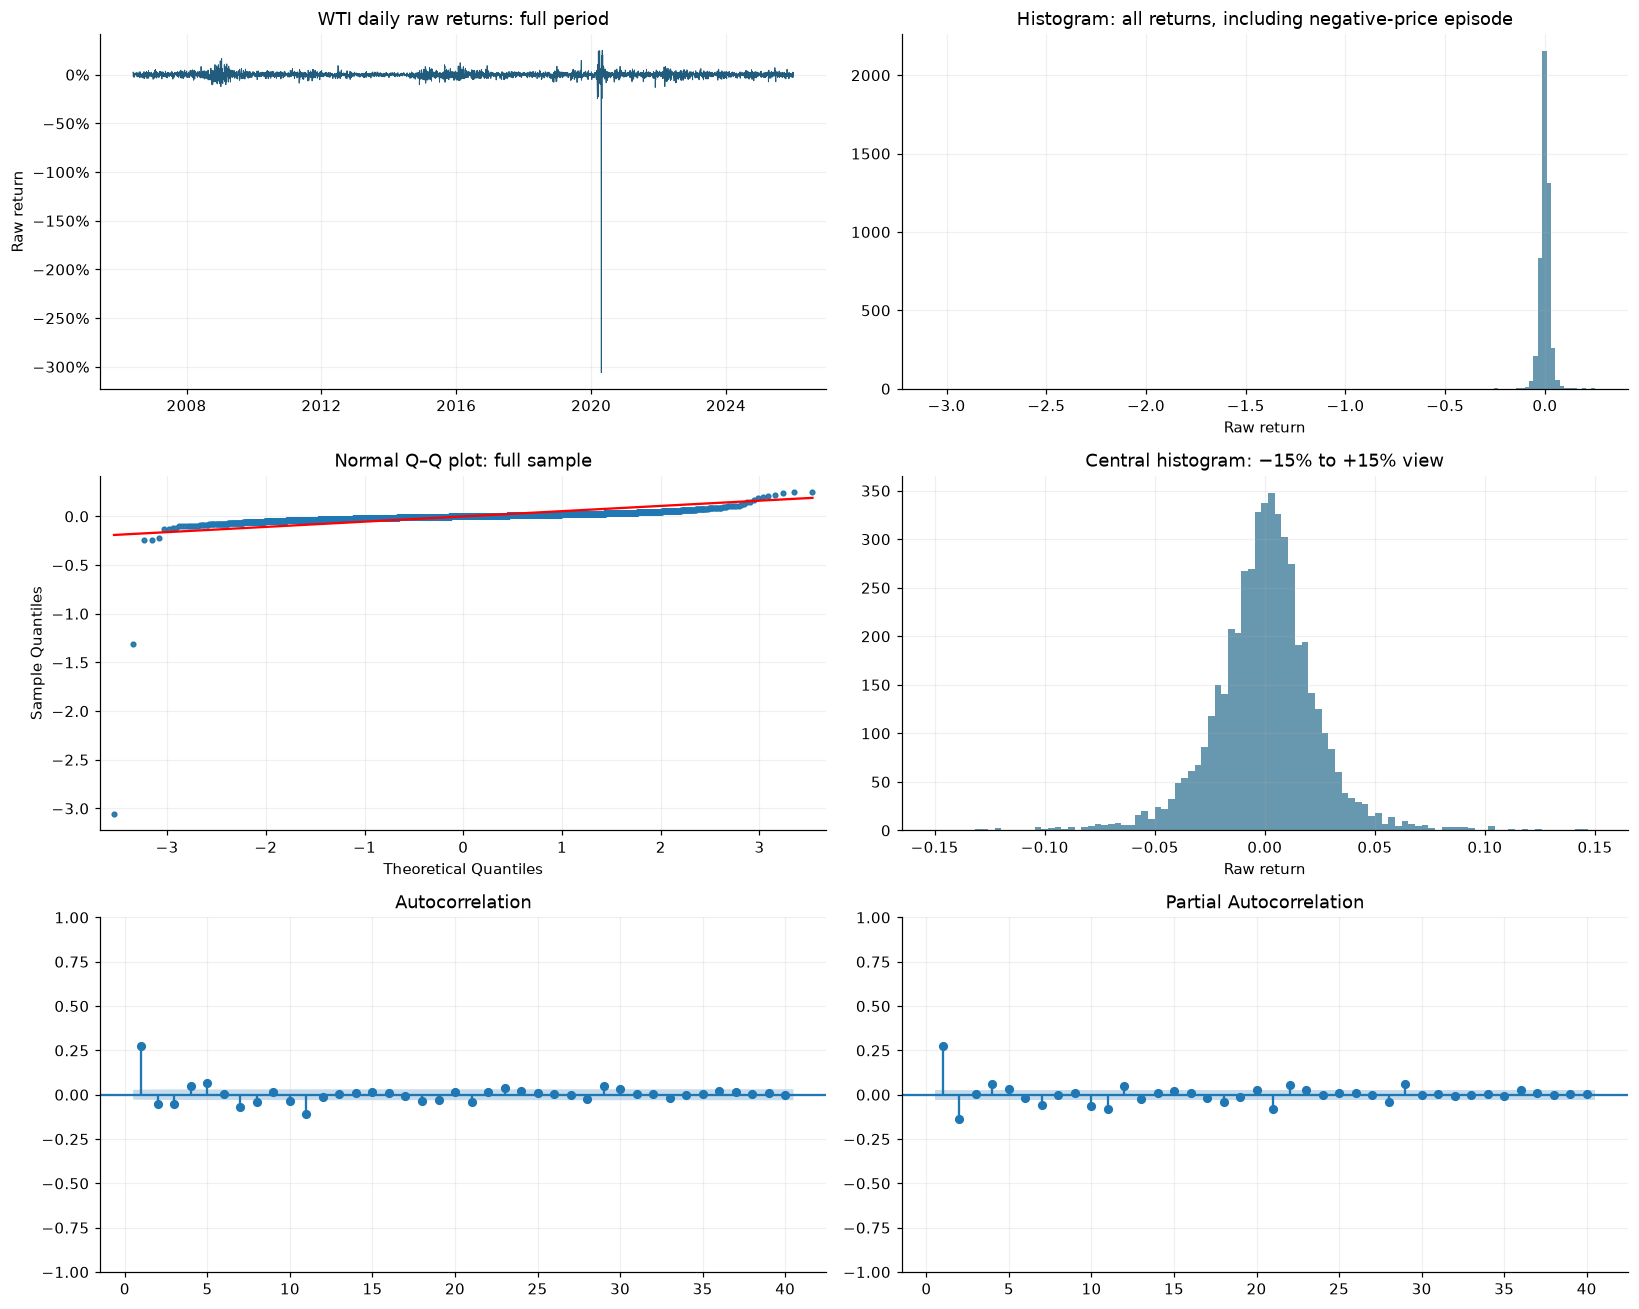

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes[0, 0].plot(returns.index, returns, lw=.6, color='#225c7c')
axes[0, 0].set(title='WTI daily raw returns: full period', ylabel='Raw return')
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0, 1].hist(returns, bins=150, color='#427e9b', alpha=.8)
axes[0, 1].set(title='Histogram: all returns, including negative-price episode', xlabel='Raw return')
qqplot(returns, line='s', ax=axes[1, 0], markerfacecolor='#427e9b', markersize=3)
axes[1, 0].set_title('Normal Q–Q plot: full sample')
axes[1, 1].hist(returns, bins=np.linspace(-.15, .15, 100), color='#427e9b', alpha=.8)
axes[1, 1].set(title='Central histogram: −15% to +15% view', xlabel='Raw return')
plot_acf(returns, lags=40, zero=False, ax=axes[2, 0])
plot_pacf(returns, lags=40, zero=False, method='ywm', ax=axes[2, 1])
fig.tight_layout()
fig.savefig(RESULTS / 'exploration.png', bbox_inches='tight')
plt.show()

## 4. Normality and serial dependence

Shapiro–Wilk, Jarque–Bera, and Anderson–Darling test marginal normality;
Ljung–Box tests return autocorrelation at lags 3, 5, and 10. Their usual
p-values assume conditions that may be violated by volatility clustering;
read these as diagnostics. Failure to reject is not proof of normality or
independence. If the sample exceeds 5,000 observations, report Shapiro's full
sample statistic with its approximate p-value and a seeded 5,000-point check.

In [5]:
with warnings.catch_warnings(record=True) as shapiro_warnings:
    sw = stats.shapiro(returns.to_numpy())
jb = stats.jarque_bera(returns)
ad_stat, ad_p = normal_ad(returns.to_numpy())
normality = pd.DataFrame([
    {'test': 'Shapiro–Wilk', 'n': len(returns), 'statistic': sw.statistic, 'p_value': sw.pvalue},
    {'test': 'Jarque–Bera', 'n': len(returns), 'statistic': jb.statistic, 'p_value': jb.pvalue},
    {'test': 'Anderson–Darling (estimated normal mean/variance)', 'n': len(returns),
     'statistic': ad_stat, 'p_value': ad_p},
]).set_index('test')
normality['reject_at_5pct'] = normality.p_value < .05
display(normality)
for warning in shapiro_warnings:
    print(str(warning.message))
if len(returns) > 5000:
    sample = np.random.default_rng(SEED).choice(returns.to_numpy(), 5000, replace=False)
    print('Seeded 5,000-observation Shapiro sensitivity:', stats.shapiro(sample))
ljung_box = acorr_ljungbox(returns, lags=[3, 5, 10], model_df=0, return_df=True)
display(ljung_box)
normality.to_csv(RESULTS / 'normality_tests.csv')
ljung_box.to_csv(RESULTS / 'ljung_box.csv')

/Users/andreikh./Repositories/var-estimation/.venv/lib/python3.14/site-packages/statsmodels/stats/_adnorm.py:71: RuntimeWarning: divide by zero encountered in log
  ad_values = (2 * i[sl1] - 1.0) / nobs * (np.log(z) + np.log1p(-z[sl2]))


,n,statistic,p_value,reject_at_5pct
test,,,,
Shapiro–Wilk,4934,2.591107e-01,1.531623e-88,True
Jarque–Bera,4934,9.746552e+08,0.000000e+00,True
Anderson–Darling (estimated normal mean/variance),4934,inf,0.000000e+00,True


,lb_stat,lb_pvalue
3,394.966597,2.725266e-85
5,428.327271,2.319719e-90
10,469.065863,1.785191e-94


## 5. Fit four unconditional distributions on 2006–2017

Fit normal (2 parameters), Student-t (3), Hansen asymmetric Student-t (4),
and generalized hyperbolic (5). All likelihoods use decimal returns and
the same observations; $AIC=2k-2\ell$, $BIC=k\log(n)-2\ell$.
Lower is better within this comparison. GH uses multiple optimization starts
with explicit numerical bounds; inspect its convergence and boundary flag.

References: [SciPy GH parameterization](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.genhyperbolic.html),
[Hansen skew-t implementation](https://arch.readthedocs.io/en/latest/univariate/generated/arch.univariate.SkewStudent.html).

In [6]:
distribution_fits, distribution_comparison = fit_distributions(development)
display(distribution_comparison.sort_values('AIC'))
display(pd.Series({name: fit['params'].tolist() for name, fit in distribution_fits.items()}, name='parameters'))
distribution_comparison.to_csv(RESULTS / 'distribution_comparison.csv')
gh_params = distribution_fits['GH']['params']  # p, a, b, loc, scale

,converged,loglik,k,n,AIC,BIC,boundary,optimizer_message
GH,True,7032.50249,5,2921,-14055.00498,-14025.106574,False,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Student-t,True,7029.036467,3,2921,-14052.072934,-14034.13389,NaN,NaN
Hansen skew-t,True,7029.832544,4,2921,-14051.665088,-14027.746363,NaN,NaN
Normal,True,6824.094142,2,2921,-13644.188284,-13632.228922,NaN,NaN


Normal                                        [0.000216, 0.023397]
Student-t                            [3.630853, 0.000269, 0.01631]
Hansen skew-t           [3.613474, -0.030865, -0.000028, 0.024379]
GH               [-0.685651, 0.726711, -0.015642, 0.000611, 0.0...
Name: parameters, dtype: object

## 6. GH Monte Carlo: 10,000 draws

Simulate from the fitted development-period GH distribution. Compare its exact
5% **return** quantile with the simulated 5% return quantile. Their negatives
are the requested 95% loss quantiles. Simulation error explains a small gap.

,signed_return_threshold,positive_loss_VaR_95
GH exact,-0.036656,0.036656
Monte Carlo,-0.036320,0.036320


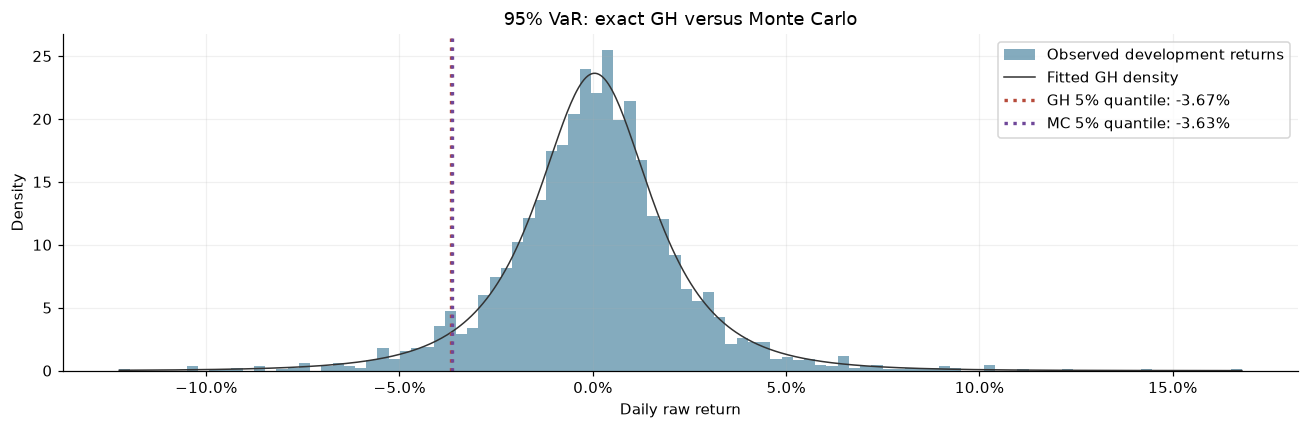

In [7]:
rng = np.random.default_rng(SEED)
simulation = stats.genhyperbolic.rvs(*gh_params, size=10_000, random_state=rng)
gh_q = float(stats.genhyperbolic.ppf(ALPHA, *gh_params))
mc_q = float(np.quantile(simulation, ALPHA))
display(pd.DataFrame({'signed_return_threshold': [gh_q, mc_q],
                      'positive_loss_VaR_95': [-gh_q, -mc_q]}, index=['GH exact', 'Monte Carlo']))
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(development, bins=100, density=True, alpha=.65, color='#427e9b', label='Observed development returns')
grid = np.linspace(development.min(), development.max(), 600)
ax.plot(grid, stats.genhyperbolic.pdf(grid, *gh_params), color='#333333', lw=1, label='Fitted GH density')
ax.axvline(gh_q, ls=':', lw=2.2, color='#b64a3a', label=f'GH 5% quantile: {gh_q:.2%}')
ax.axvline(mc_q, ls=':', lw=2.2, color='#6f4799', label=f'MC 5% quantile: {mc_q:.2%}')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='95% VaR: exact GH versus Monte Carlo', xlabel='Daily raw return', ylabel='Density')
ax.legend(); fig.tight_layout(); plt.show()

## 7. Rolling GH VaR, 2018–2025

This is **rolling parametric GH VaR**, rather than pure historical simulation:
each date fits GH to the immediately previous 504 observations. A true
historical-simulation threshold is also computed for reference using the
empirical 5% quantile. It is not one of the final three selected models.

The development-period GH parameters are used only in section 6. Rolling models
are refitted on their own windows. GH uses independent multistart fits, allowing
local parallel execution. Yesterday's GARCH or CAViaR fit may initialize today's
optimizer, but no future returns or full-test estimates enter it.
Each checkpoint records training dates, convergence, parameters and warnings.
Failed estimates block the backtests instead of silently changing the sample.

GH: daily refits: 0it [00:00, ?it/s]

GH: daily refits: 0it [00:00, ?it/s]

,train_start,train_end,n_train,q,status,boundary
date,,,,,,
2018-01-02,2015-12-31T00:00:00,2017-12-29T00:00:00,504,-0.037825,ok,False
2018-01-03,2016-01-04T00:00:00,2018-01-02T00:00:00,504,-0.037799,ok,False
2018-01-04,2016-01-05T00:00:00,2018-01-03T00:00:00,504,-0.037869,ok,False
2018-01-05,2016-01-06T00:00:00,2018-01-04T00:00:00,504,-0.037898,ok,False
2018-01-08,2016-01-07T00:00:00,2018-01-05T00:00:00,504,-0.037299,ok,False


GH fits on numerical bounds: 682


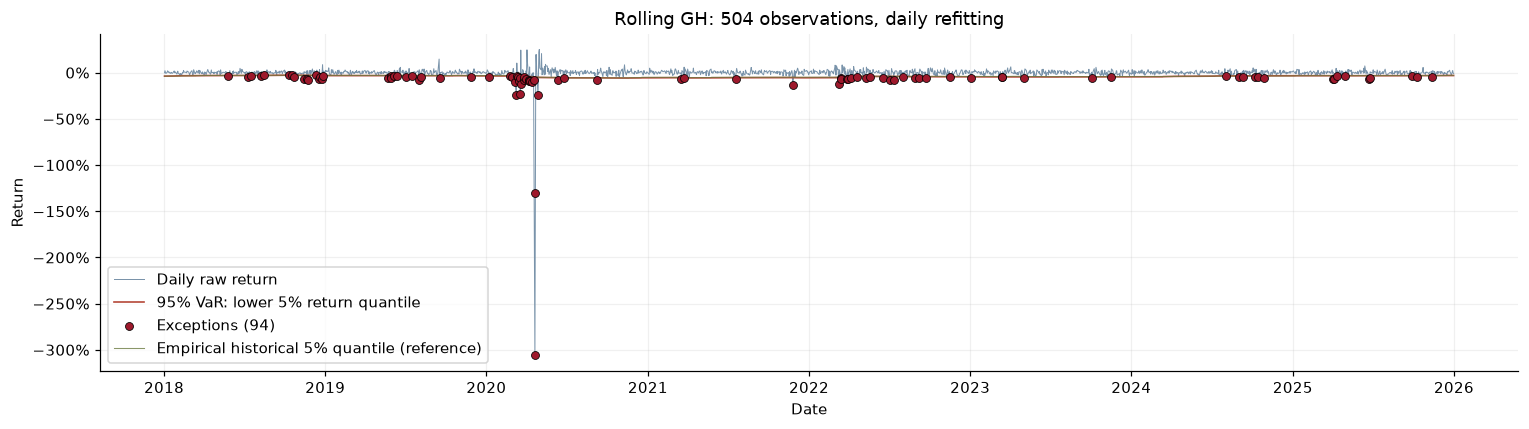

In [8]:
gh_rolling = rolling_forecasts(returns, 'GH', TEST_START, TEST_END,
                               window=WINDOW, alpha=ALPHA, output_dir=RESULTS, gh_workers=GH_WORKERS)
gh_var = complete_quantiles(gh_rolling).rename('Rolling GH')
historical_var = returns.shift(1).rolling(WINDOW).quantile(ALPHA).loc[test.index]
display(gh_rolling[['train_start', 'train_end', 'n_train', 'q', 'status', 'boundary']].head())
print('GH fits on numerical bounds:', int(gh_rolling.boundary.sum()))
ax = plot_var(test, gh_var, 'Rolling GH: 504 observations, daily refitting')
ax.plot(historical_var.index, historical_var, color='#6d7c42', lw=.7, alpha=.8,
        label='Empirical historical 5% quantile (reference)')
ax.legend(); plt.tight_layout(); plt.show()

## 8. GH coverage tests and three losses

Kupiec checks unconditional 5% exception frequency. Christoffersen reports
independence and conditional coverage (independence plus Kupiec).
The exact binomial p-value is included as a finite-sample coverage diagnostic.
The DQ test uses a constant, four lagged centered hits, and the current forecast.
All tests use asymptotic reference distributions except the exact binomial test.
Sparse transition rows and unidentified tests are explicitly flagged.

In [9]:
gh_backtest = backtest(test, gh_var, ALPHA)
display(gh_backtest.to_frame('Rolling GH'))
gh_backtest.to_csv(RESULTS / 'GH_backtest.csv')

,Rolling GH
n,2013
exceptions,94
rate,0.046696
LR_uc,0.472476
p_uc,0.49185
p_binomial,0.539315
n00,1838
n01,80
n10,80
n11,14


## 9. GARCH family: development-period quality

Fit a constant mean and **standardized Student-t innovations** for all three
specifications: GARCH(1,1), GARCH(2,2), and GJR-GARCH(1,1).
For GJR, the variance has an additional $\gamma\epsilon_{t-1}^2I(\epsilon_{t-1}<0)$ term.
This is an explicit choice of innovation distribution, held fixed across models.

Numerical estimation uses percentage returns (100 × raw returns). The table
converts log-likelihoods back to decimal-return units with
$\ell_r=\ell_{100r}+n\log(100)$ before calculating AIC/BIC.
[arch forecasting documentation](https://arch.readthedocs.io/en/stable/univariate/univariate_volatility_forecasting.html).

In [10]:
garch_fits = {name: fit_garch(development, name) for name in GARCH_SPECS}
garch_comparison = pd.DataFrame({
    name: information_criteria(fit.loglikelihood + fit.nobs * np.log(100), fit.num_params, fit.nobs)
          | {'convergence_flag': fit.convergence_flag, 'warnings': fit.var_project_warnings}
    for name, fit in garch_fits.items()
}).T
display(garch_comparison.sort_values('AIC'))
display(pd.DataFrame({name: fit.params for name, fit in garch_fits.items()}))
garch_comparison.to_csv(RESULTS / 'garch_comparison.csv')

,loglik,k,n,AIC,BIC,convergence_flag,warnings
"GJR-GARCH(1,1)",7344.235817,6,2921,-14676.471633,-14640.593545,0,
"GARCH(1,1)",7328.292775,5,2921,-14646.585549,-14616.687143,0,
"GARCH(2,2)",7328.762502,7,2921,-14643.525004,-14601.667235,0,


,"GARCH(1,1)","GARCH(2,2)","GJR-GARCH(1,1)"
alpha[1],0.062069,5.470151e-02,0.016888
alpha[2],NaN,6.585505e-02,NaN
beta[1],0.934720,4.251218e-09,0.947621
beta[2],NaN,8.734416e-01,NaN
gamma[1],NaN,NaN,0.066872
mu,0.047706,4.947958e-02,0.020470
nu,9.848988,1.002056e+01,11.001896
omega,0.023409,4.448157e-02,0.015559


## 10. Daily rolling GJR-GARCH(1,1) VaR

For every test date fit to the preceding 504 returns and calculate
$q_t=\hat\mu_t+\hat\sigma_t z_{0.05}$, where $z_{0.05}$ is the **unit-variance**
Student-t quantile supplied by `arch`. Using an ordinary unscaled t quantile
would overstate volatility. Forecasts are converted back to decimal returns.

GJR-GARCH: daily refits: 0it [00:00, ?it/s]

GJR-GARCH: daily refits: 0it [00:00, ?it/s]

,train_start,train_end,n_train,q,status
date,,,,,
2018-01-02,2015-12-31T00:00:00,2017-12-29T00:00:00,504,-0.017945,ok
2018-01-03,2016-01-04T00:00:00,2018-01-02T00:00:00,504,-0.017598,ok
2018-01-04,2016-01-05T00:00:00,2018-01-03T00:00:00,504,-0.017345,ok
2018-01-05,2016-01-06T00:00:00,2018-01-04T00:00:00,504,-0.016959,ok
2018-01-08,2016-01-07T00:00:00,2018-01-05T00:00:00,504,-0.017235,ok


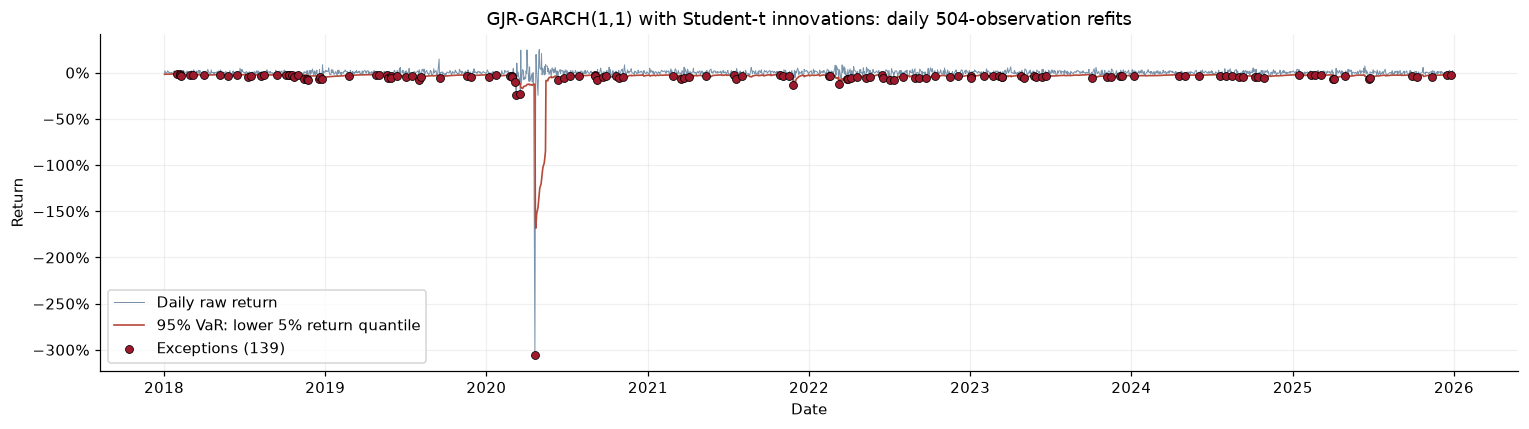

In [11]:
gjr_rolling = rolling_forecasts(returns, 'GJR-GARCH', TEST_START, TEST_END,
                                window=WINDOW, alpha=ALPHA, output_dir=RESULTS)
gjr_var = complete_quantiles(gjr_rolling).rename('GJR-GARCH')
display(gjr_rolling[['train_start', 'train_end', 'n_train', 'q', 'status']].head())
plot_var(test, gjr_var, 'GJR-GARCH(1,1) with Student-t innovations: daily 504-observation refits')
plt.tight_layout(); plt.show()

## 11. GJR-GARCH tests and losses

In [12]:
gjr_backtest = backtest(test, gjr_var, ALPHA)
display(gjr_backtest.to_frame('GJR-GARCH'))
gjr_backtest.to_csv(RESULTS / 'GJR_GARCH_backtest.csv')

,GJR-GARCH
n,2013
exceptions,139
rate,0.069051
LR_uc,13.819548
p_uc,0.000201
p_binomial,0.000183
n00,1744
n01,129
n10,129
n11,10


## 12. CAViaR(1,1): SAV, AS, and indirect GARCH

Estimate conditional quantiles by minimizing quantile loss, with
$r^+=\max(r,0)$ and $r^-=\max(-r,0)$:

$$\begin{aligned}
\text{SAV: }q_t&=\beta_0+\beta_1q_{t-1}+\beta_2|r_{t-1}|,\\
\text{AS: }q_t&=\beta_0+\beta_1q_{t-1}+\beta_2r^+_{t-1}+\beta_3r^-_{t-1},\\
\text{INDGARCH: }q_t&=-\sqrt{\beta_0+\beta_1q_{t-1}^2+\beta_2r_{t-1}^2}.
\end{aligned}$$

Multiple seeded Nelder–Mead starts address the nonsmooth objective. Estimation
uses percentage units, $0\leq\beta_1\leq0.999$, finite numerical coefficient bounds,
and nonnegative indirect-GARCH variance coefficients. Initialize from the first
75 observations in each estimation sample, then exclude these 75 observations
from the objective and in-sample scores. All three models use identical scoring dates.
These are constrained local estimates, not guarantees of a global optimum.

CAViaR does not specify a full return density. The reported **pseudo-AIC/BIC**
use an asymmetric-Laplace working likelihood with an estimated scale
$\hat s=\overline{\rho_{0.05}(r-q)}$. Count the scale in $k$.
Compare these criteria only across CAViaR specifications on the same sample;
do not rank them against the preceding density-model AIC/BIC.

In-sample DQ uses lagged hits, numerical quantile gradients, and a residual-kernel
covariance adjustment for estimated parameters. It does not apply the unadjusted
out-of-sample test to fitted quantiles. Boundary optima weaken the standard
asymptotic interpretation, and the bandwidth is reported for sensitivity checks.

Reference: [Engle & Manganelli (2004), equations and Theorems 3–5](https://www.simonemanganelli.org/Simone/Research_files/caviarPublished.pdf).

In [13]:
caviar_fits = {name: fit_caviar(development, spec=name, alpha=ALPHA, seed=SEED, starts=12)
              for name in ['SAV', 'AS', 'INDGARCH']}
caviar_rows = []
for name, fit in caviar_fits.items():
    burn = fit['burn']
    gradients = caviar_gradient(development, fit)[burn:]
    dq = dq_test(development.to_numpy()[burn:], fit['q'][burn:], ALPHA, gradient=gradients)
    caviar_rows.append({'specification': name, 'n_scored': fit['n'], 'k_including_ALD_scale': fit['k'],
                       'pseudo_AIC_ALD': fit['AIC'], 'pseudo_BIC_ALD': fit['BIC'],
                       'mean_quantile_loss': fit['quantile_loss'], 'boundary': fit['boundary'],
                       'successful_starts': fit['successful_starts'], **dq})
caviar_comparison = pd.DataFrame(caviar_rows).set_index('specification')
display(caviar_comparison)
display(pd.Series({name: fit['params'].tolist() for name, fit in caviar_fits.items()}, name='parameters (percentage units)'))
caviar_comparison.to_csv(RESULTS / 'caviar_comparison.csv')

,n_scored,k_including_ALD_scale,pseudo_AIC_ALD,pseudo_BIC_ALD,mean_quantile_loss,boundary,successful_starts,DQ,p_DQ,df,status,bandwidth,kernel_observations
specification,,,,,,,,,,,,,
SAV,2846,4,-11483.021398,-11459.206719,0.002321,False,12,5.865259,0.209439,4,asymptotic,0.004489,114
AS,2846,5,-11557.593735,-11527.825386,0.002290,False,12,9.081553,0.059093,4,asymptotic,0.004365,128
INDGARCH,2846,4,-11487.738065,-11463.923386,0.002319,False,12,7.444762,0.114170,4,asymptotic,0.004459,112


SAV                   [-0.058353, 0.924195, -0.124555]
AS          [-0.028257, 0.96657, -0.002905, -0.103395]
INDGARCH                 [0.176391, 0.920356, 0.18132]
Name: parameters (percentage units), dtype: object

## 13. Rolling AS-CAViaR VaR, 2018–2025

Refit AS on exactly 504 prior returns each day. The first 75 observations
initialize the recursion; 429 observations enter each optimization objective.
The next forecast uses the final fitted quantile and the last observed return.
The full-development fit is not reused as a fixed test-period model.

AS-CAViaR: daily refits: 0it [00:00, ?it/s]

AS-CAViaR: daily refits: 0it [00:00, ?it/s]

,train_start,train_end,n_train,q,status,boundary
date,,,,,,
2018-01-02,2015-12-31T00:00:00,2017-12-29T00:00:00,504,-0.036726,ok,False
2018-01-03,2016-01-04T00:00:00,2018-01-02T00:00:00,504,-0.034665,ok,False
2018-01-04,2016-01-05T00:00:00,2018-01-03T00:00:00,504,-0.038931,ok,True
2018-01-05,2016-01-06T00:00:00,2018-01-04T00:00:00,504,-0.036030,ok,True
2018-01-08,2016-01-07T00:00:00,2018-01-05T00:00:00,504,-0.033156,ok,True


AS fits on numerical bounds: 729


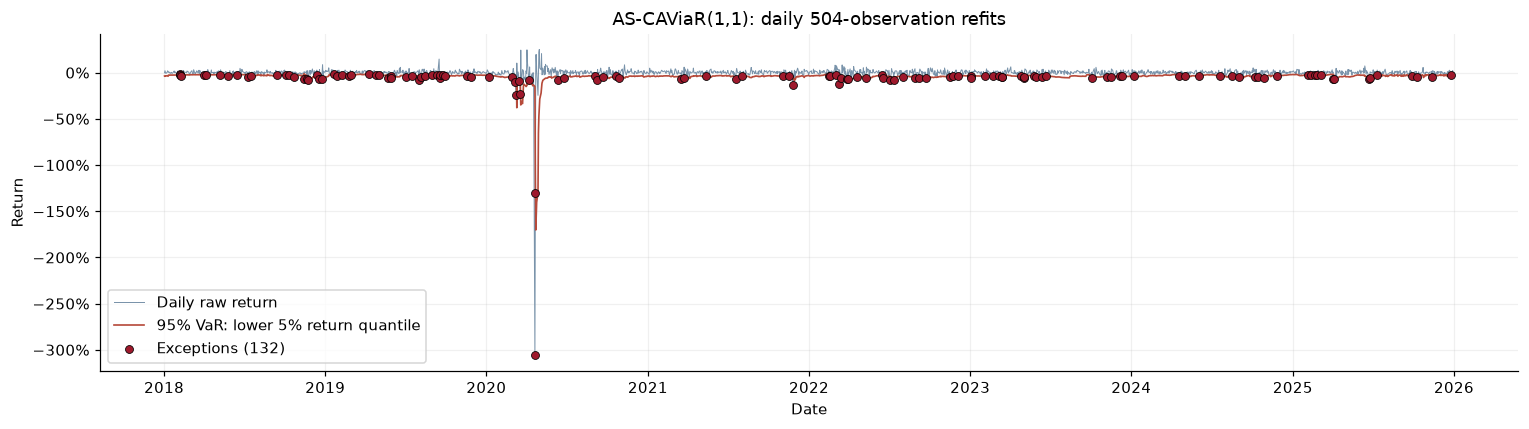

In [14]:
as_rolling = rolling_forecasts(returns, 'AS-CAViaR', TEST_START, TEST_END,
                               window=WINDOW, alpha=ALPHA, caviar_starts=5, output_dir=RESULTS)
as_var = complete_quantiles(as_rolling).rename('AS-CAViaR')
display(as_rolling[['train_start', 'train_end', 'n_train', 'q', 'status', 'boundary']].head())
print('AS fits on numerical bounds:', int(as_rolling.boundary.sum()))
plot_var(test, as_var, 'AS-CAViaR(1,1): daily 504-observation refits')
plt.tight_layout(); plt.show()

## 14. AS-CAViaR and consolidated test-period diagnostics

The out-of-sample DQ p-values and likelihood-ratio coverage tests are standard
asymptotic diagnostics. Fixed-length overlapping estimation windows and repeated
parameter estimation can affect their finite-sample calibration. Inspect exception
patterns and losses alongside p-values; do not treat a non-rejection as validation
of every model assumption. All three models must cover **every identical test date**.

In [15]:
as_backtest = backtest(test, as_var, ALPHA)
display(as_backtest.to_frame('AS-CAViaR'))
forecasts = pd.concat([gh_var, gjr_var, as_var], axis=1)
assert forecasts.index.equals(test.index) and np.isfinite(forecasts).all().all()
backtests = pd.DataFrame({name: backtest(test, forecasts[name], ALPHA) for name in forecasts}).T
display(backtests[['n', 'exceptions', 'rate', 'p_uc', 'p_ind', 'p_cc', 'DQ_p_DQ',
                   'Lopez_mean', 'Blanco_Ihle_mean', 'Quantile_mean']])
backtests.to_csv(RESULTS / 'all_backtests.csv')
pd.concat([test, forecasts], axis=1).to_csv(RESULTS / 'test_returns_and_var.csv')
yearly_coverage = pd.DataFrame({name: (test < forecasts[name]).groupby(test.index.year).mean()
                                for name in forecasts})
display(yearly_coverage)
yearly_coverage.to_csv(RESULTS / 'annual_exception_rates.csv')

,AS-CAViaR
n,2013
exceptions,132
rate,0.065574
LR_uc,9.401097
p_uc,0.002169
p_binomial,0.002109
n00,1758
n01,122
n10,122
n11,10


,n,exceptions,rate,p_uc,p_ind,p_cc,DQ_p_DQ,Lopez_mean,Blanco_Ihle_mean,Quantile_mean
Rolling GH,2013,94,0.046696,0.49185,0.000085,0.000352,0.0,0.052088,0.076385,0.005305
GJR-GARCH,2013,139,0.069051,0.000201,0.89114,0.000989,0.001116,0.073378,0.043738,0.004745
AS-CAViaR,2013,132,0.065574,0.002169,0.633281,0.008112,0.001335,0.06986,0.046082,0.004613


,Rolling GH,GJR-GARCH,AS-CAViaR
date,,,
2018,0.063492,0.107143,0.079365
2019,0.043651,0.059524,0.095238
2020,0.098814,0.083004,0.063241
2021,0.015873,0.047619,0.031746
2022,0.067729,0.079681,0.079681
2023,0.024000,0.072000,0.076000
2024,0.023810,0.047619,0.043651
2025,0.035857,0.055777,0.055777


## 15. Final comparison graph

The first panel preserves the full range, including the negative-price episode.
The second panel is a labeled central zoom; outliers outside that range remain
visible in the first panel. Exception markers on individual models are above.

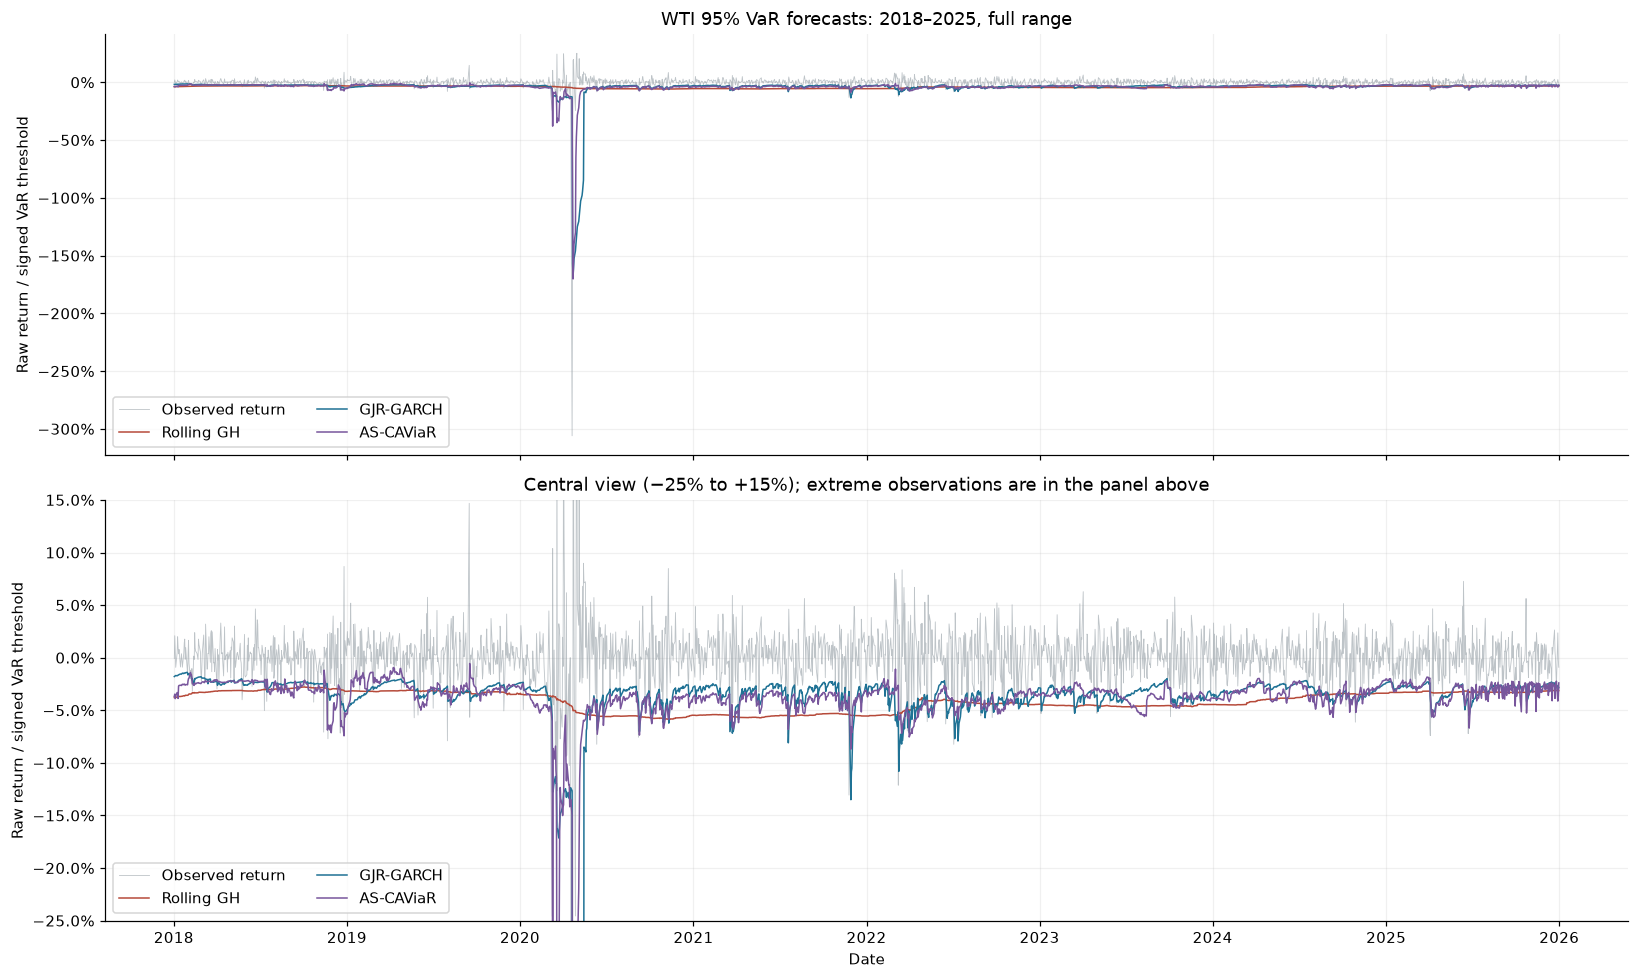

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
colors = {'Rolling GH': '#b64a3a', 'GJR-GARCH': '#1f7295', 'AS-CAViaR': '#78569c'}
for ax in axes:
    ax.plot(test.index, test, lw=.55, alpha=.55, color='#89949c', label='Observed return')
    for name in forecasts:
        ax.plot(forecasts.index, forecasts[name], color=colors[name], lw=1, label=name)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel('Raw return / signed VaR threshold')
    ax.legend(loc='lower left', ncol=2)
axes[0].set_title('WTI 95% VaR forecasts: 2018–2025, full range')
axes[1].set_ylim(-.25, .15)
axes[1].set_title('Central view (−25% to +15%); extreme observations are in the panel above')
axes[1].set_xlabel('Date')
fig.tight_layout()
fig.savefig(RESULTS / 'final_var_comparison.png', bbox_inches='tight')
plt.show()

## 16. Pairwise Diebold–Mariano tests

Compare daily **quantile losses** for the three selected models on identical
test dates. The difference is loss(A) − loss(B), so a **negative DM statistic
favors A**. Use a Bartlett/Newey–West long-run variance with a reported bandwidth,
a one-step Harvey–Leybourne–Newbold correction, and two-sided t reference
p-values. Holm-adjust the three pairwise p-values. The HAC correction allows
serial dependence but does not remove the effects of structural breaks; results
remain asymptotic. Degenerate loss differences produce an explicit undefined test.

References: [Diebold & Mariano, Comparing Predictive Accuracy](https://doi.org/10.1080/07350015.1995.10524599),
[Harvey, Leybourne & Newbold (1997)](https://doi.org/10.1016/S0169-2070(96)00719-4).

In [17]:
dm_results = pairwise_dm(test, forecasts, ALPHA)
display(dm_results)
dm_results.to_csv(RESULTS / 'pairwise_diebold_mariano.csv', index=False)
run_metadata = {'asset': 'WTI', 'source': 'TankerMap MAX feed',
                'study_start': STUDY_START, 'study_end': STUDY_END, 'train_end': TRAIN_END,
                'validation_start': VALID_START, 'validation_end': VALID_END,
                'test_start': TEST_START, 'test_end': TEST_END, 'alpha': ALPHA,
                'window_observations': WINDOW, 'seed': SEED, 'versions': versions,
                'n_returns': len(returns), 'n_test': len(test)}
(RESULTS / 'run_metadata.json').write_text(json.dumps(run_metadata, indent=2))
print('All 17 numbered stages completed. Tables, forecasts, plots, and metadata are in results/.')

,model_A,model_B,DM,p_value,mean_difference,hac_lags,status,p_Holm
0,Rolling GH,GJR-GARCH,0.891852,0.372579,0.000560,7,ok,0.745158
1,Rolling GH,AS-CAViaR,1.368777,0.171222,0.000692,7,ok,0.513665
2,GJR-GARCH,AS-CAViaR,0.576036,0.564655,0.000132,7,ok,0.745158


All 17 numbered stages completed. Tables, forecasts, plots, and metadata are in results/.


### Reading the results

Prefer lower out-of-sample quantile loss, then assess coverage, clustering, and
the DM uncertainty. Do not choose a model from test-period performance and then
describe those same dates as an untouched validation sample. Boundary fits,
the negative-price episode, structural changes, and undocumented futures rolls
are substantive limitations. Purely statistical distribution fits may assign
probability to returns outside ordinary positive-price investment bounds.

Additional loss/backtesting references:
[Lopez (1999)](https://www.frbsf.org/economic-research/wp-content/uploads/sites/4/3-17.pdf),
[VaR loss definitions including Blanco–Ihle, equations 35–36](https://www.feem.it/wp-content/uploads/NDL2009-024.pdf).